# Redes Neuronales V: Reconocimiento facial con Redes Neuronales Siamesas

**Estudiante:** Juan Camilo Cruz Beltran  
**Universidad:** Universidad de Cundinamarca. Especialización en Inteligencia Artificial  
**Framework:** PyTorch + `facenet-pytorch`  

## 1. Objetivo y consentimiento de las imágenes

**Objetivo:** implementar una red neuronal siamesa que convierta rostros en *embeddings* y permita verificar
si dos fotografías corresponden a la misma persona, usando **Triplet Loss** y evaluando los escenarios de
**One-shot**, **Few-shot** y **Zero-shot Learning**.

**Consentimiento:** todas las imágenes del dataset son del propio autor o de personas que autorizaron
explícitamente el uso de sus fotografías con fines académicos. Las personas se identifican con códigos
(`persona_01`, `persona_02`, ...) y las fotografías no se publican en el repositorio.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 2. Configuración del entorno

Requiere **GPU** (Entorno de ejecución → Cambiar tipo de entorno → GPU T4).

`facenet-pytorch` es una librería antigua y llama a `torchvision._is_tracing`, que las versiones nuevas de
`torchvision` ya no exponen. Se define un parche mínimo para mantener la compatibilidad.

In [ ]:
!pip install facenet-pytorch --no-deps -q

import os
import torch
import torchvision
from PIL import Image
import matplotlib.pyplot as plt
from facenet_pytorch import MTCNN

# Parche de compatibilidad (facenet-pytorch vs torchvision nuevo)
torchvision._is_tracing = lambda: False

from google.colab import drive
drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Usando:", device)
print("Parche activo:", torchvision._is_tracing())

RUTA = '/content/drive/MyDrive/Dataset'
SALIDA = '/content/drive/MyDrive/Dataset_recortado'

Mounted at /content/drive
Usando: cuda
Parche activo: False


## 3. Dataset y organización

Una carpeta por persona, con fotografías de distintas poses y condiciones (frente, ángulos laterales,
arriba/abajo, expresiones y con gorra):

```
Dataset/
  Persona_1/ ... Persona_5/

In [ ]:
RUTA = '/content/drive/MyDrive/Dataset'
for p in sorted(os.listdir(RUTA)):
    print(p, len(os.listdir(f'{RUTA}/{p}')), "fotos")

Persona_1 10 fotos
Persona_2 10 fotos
Persona_3 10 fotos
Persona_4 10 fotos
Persona_5 10 fotos


## 4. Preprocesamiento: detección y recorte de rostros

Se usa **MTCNN** para detectar el rostro en cada fotografía, recortarlo con un margen de 20 px y
redimensionarlo a **160×160**, el tamaño de entrada de la red. Esto elimina el fondo, unifica el tamaño de
las entradas y centra el aprendizaje en el rostro. Las imágenes originales no se modifican: los recortes se
guardan en otra carpeta.

In [ ]:
SALIDA = '/content/drive/MyDrive/Dataset_recortado'
mtcnn = MTCNN(image_size=160, margin=20, device=device)

fallos = []
for persona in sorted(os.listdir(RUTA)):
    os.makedirs(f'{SALIDA}/{persona}', exist_ok=True)
    for nombre in sorted(os.listdir(f'{RUTA}/{persona}')):
        img = Image.open(f'{RUTA}/{persona}/{nombre}').convert('RGB')
        rostro = mtcnn(img, save_path=f'{SALIDA}/{persona}/{nombre}')
        if rostro is None:
            fallos.append(f'{persona}/{nombre}')

print("Fotos donde NO se detectó rostro:", len(fallos))
print(fallos)

Fotos donde NO se detectó rostro: 0
[]


Verificación visual de los recortes (evidencia del preprocesamiento):

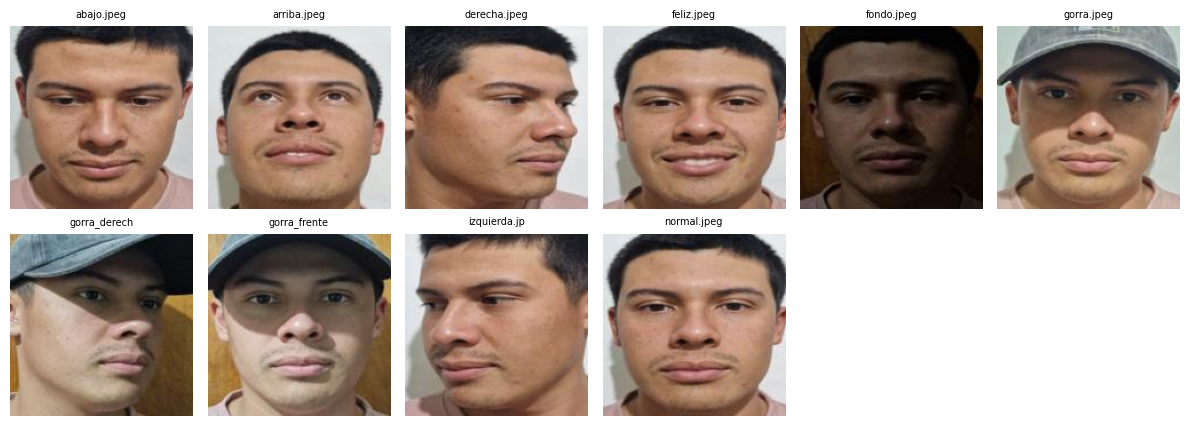

In [ ]:
SALIDA = '/content/drive/MyDrive/Dataset_recortado'

def mostrar_persona(persona, cols=6):
    archivos = sorted(os.listdir(f'{SALIDA}/{persona}'))
    filas = (len(archivos) + cols - 1) // cols
    plt.figure(figsize=(cols * 2, filas * 2.2))
    for i, nombre in enumerate(archivos):
        img = Image.open(f'{SALIDA}/{persona}/{nombre}')
        plt.subplot(filas, cols, i + 1)
        plt.imshow(img)
        plt.title(nombre.replace(f'{persona}_', '')[:12], fontsize=7)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

mostrar_persona('Persona_5')

## 5. Separación entrenamiento / prueba / One-shot

- **Entrenamiento:** 7 fotos por persona.
- **Prueba:** 3 fotos por persona (no se usan al entrenar).
- **One-shot:** la última persona queda **fuera del entrenamiento**; se usa para evaluar el
  reconocimiento de alguien que la red no vio durante el fine-tuning.

Se fija la semilla aleatoria para que la separación sea reproducible.

In [ ]:
import random
random.seed(42)   # para que sea reproducible

PERSONA_ONESHOT = 'Persona_5'   # queda fuera del entrenamiento
N_TRAIN = 7

train, test, oneshot = {}, {}, {}

for persona in sorted(os.listdir(SALIDA)):
    archivos = sorted(os.listdir(f'{SALIDA}/{persona}'))
    rutas = [f'{SALIDA}/{persona}/{a}' for a in archivos]
    random.shuffle(rutas)

    if persona == PERSONA_ONESHOT:
        oneshot[persona] = rutas
    else:
        train[persona] = rutas[:N_TRAIN]
        test[persona] = rutas[N_TRAIN:]

for p in train:
    print(p, "-> train:", len(train[p]), "| test:", len(test[p]))
print(PERSONA_ONESHOT, "-> one-shot:", len(oneshot[PERSONA_ONESHOT]))

Persona_1 -> train: 7 | test: 3
Persona_2 -> train: 7 | test: 3
Persona_3 -> train: 7 | test: 3
Persona_4 -> train: 7 | test: 3
Persona_5 -> one-shot: 10


## 6. Generador de tripletas y data augmentation

Cada ejemplo de entrenamiento es una **tripleta**:
- **Ancla (A):** una foto de la persona X.
- **Positivo (P):** otra foto de la persona X.
- **Negativo (N):** una foto de una persona distinta.

Para entrenamiento se aplica *data augmentation* (giro horizontal y variación de brillo y contraste),
porque hay pocas imágenes. Para prueba solo se normaliza. Los píxeles quedan en el rango [-1, 1].

In [ ]:
import random
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Entrenamiento: con variaciones aleatorias
tf_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),   # deja los píxeles en [-1, 1]
])

# Prueba: sin variaciones
tf_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

class TripletDataset(Dataset):
    def __init__(self, datos, transform, n_tripletas=600):
        self.datos = datos                    # dict: persona -> lista de rutas
        self.personas = list(datos.keys())
        self.transform = transform
        self.n = n_tripletas

    def __len__(self):
        return self.n

    def _cargar(self, ruta):
        return self.transform(Image.open(ruta).convert('RGB'))

    def __getitem__(self, idx):
        p_ancla = random.choice(self.personas)
        ruta_a, ruta_p = random.sample(self.datos[p_ancla], 2)   # 2 fotos distintas
        p_neg = random.choice([p for p in self.personas if p != p_ancla])
        ruta_n = random.choice(self.datos[p_neg])
        return self._cargar(ruta_a), self._cargar(ruta_p), self._cargar(ruta_n)

ds_train = TripletDataset(train, tf_train, n_tripletas=600)
dl_train = DataLoader(ds_train, batch_size=16, shuffle=True)

Verificación de una tripleta (ancla y positivo = misma persona; negativo = otra):

torch.Size([3, 160, 160]) torch.Size([3, 160, 160]) torch.Size([3, 160, 160])


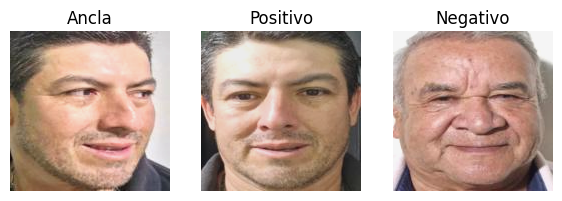

In [ ]:
a, p, n = ds_train[0]
print(a.shape, p.shape, n.shape)

def ver(t):
    return t.permute(1, 2, 0).add(1).div(2).clamp(0, 1)

plt.figure(figsize=(7, 3))
for i, (t, titulo) in enumerate(zip([a, p, n], ['Ancla', 'Positivo', 'Negativo'])):
    plt.subplot(1, 3, i + 1)
    plt.imshow(ver(t))
    plt.title(titulo)
    plt.axis('off')
plt.show()

## 7. Arquitectura de la red siamesa

- **Red base:** `InceptionResnetV1` preentrenada en **VGGFace2**. Recibe un rostro de 160×160 y
  produce un **embedding de 512 dimensiones**.
- **Siamesa:** la *misma* red, con los *mismos* pesos, procesa ancla, positivo y negativo.
- **Fine-tuning:** como el dataset es pequeño, se congela casi toda la red y solo se entrenan
  `block8`, `last_linear` y `last_bn`. Así se evita el sobreajuste y se aprovecha el conocimiento previo.

In [ ]:
import torch.nn as nn
from facenet_pytorch import InceptionResnetV1

model = InceptionResnetV1(pretrained='vggface2').to(device)

# Congelar todo
for p in model.parameters():
    p.requires_grad = False

# Descongelar solo las últimas capas
for capa in [model.block8, model.last_linear, model.last_bn]:
    for p in capa.parameters():
        p.requires_grad = True

entrenables = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Parámetros entrenables: {entrenables:,} de {total:,}")

  0%|          | 0.00/107M [00:00<?, ?B/s]

Parámetros entrenables: 2,519,296 de 27,910,327


## 8. Triplet Loss y entrenamiento

La Triplet Loss exige que el ancla quede más cerca del positivo que del negativo por al menos un margen $m$:

$$\mathcal{L}(A,P,N) = \max\big(\,d(A,P) - d(A,N) + m,\; 0\,\big)$$

donde $d$ es la distancia euclidiana entre embeddings. Si el negativo ya está más lejos que el positivo por más
que el margen, la pérdida es 0 y esa tripleta no aporta aprendizaje. Aquí $m = 0.5$.

Época 1/10 - loss: 0.0000
Época 2/10 - loss: 0.0000
Época 3/10 - loss: 0.0000
Época 4/10 - loss: 0.0000
Época 5/10 - loss: 0.0000
Época 6/10 - loss: 0.0000
Época 7/10 - loss: 0.0000
Época 8/10 - loss: 0.0000
Época 9/10 - loss: 0.0000
Época 10/10 - loss: 0.0000


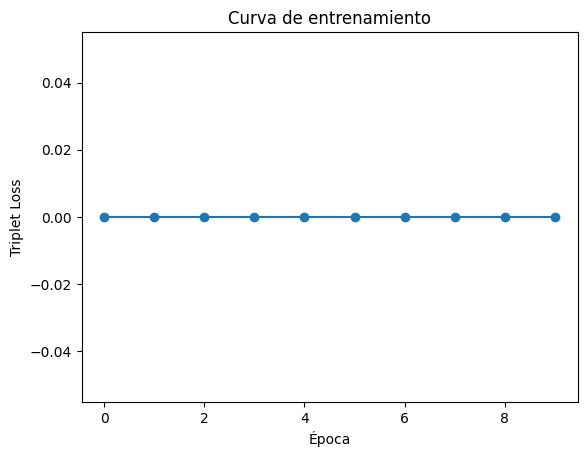

In [ ]:
import torch.optim as optim

loss_fn = nn.TripletMarginLoss(margin=0.5, p=2)
optimizer = optim.Adam(
    [p for p in model.parameters() if p.requires_grad], lr=1e-4
)

EPOCAS = 10
historial = []

model.eval()   # mantiene fijas las estadísticas de BatchNorm de las capas congeladas
for epoca in range(EPOCAS):
    total_loss = 0
    for a, p, n in dl_hard:
        a, p, n = a.to(device), p.to(device), n.to(device)
        ea, ep, en = model(a), model(p), model(n)   # misma red, tres entradas

        loss = loss_fn(ea, ep, en)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    promedio = total_loss / len(dl_hard)
    historial.append(promedio)
    print(f"Época {epoca+1}/{EPOCAS} - loss: {promedio:.4f}")

plt.plot(historial, marker='o')
plt.xlabel('Época'); plt.ylabel('Triplet Loss')
plt.title('Curva de entrenamiento')
plt.show()

torch.save(model.state_dict(), '/content/drive/MyDrive/siamesa_rostros.pt')

**Observación:** la pérdida es casi 0 desde la primera época. El modelo preentrenado ya separa muy bien a las
personas del dataset, por lo que la mayoría de las tripletas ya cumplen la condición del margen.

Para hacer el entrenamiento más exigente se prueba **hard negative mining**: para cada ancla se elige como
negativo la foto de otra persona **más cercana** en el espacio de embeddings.

In [ ]:
@torch.no_grad()
def embeddings_de(datos):
    model.eval()
    emb = {}
    for persona, rutas in datos.items():
        x = torch.stack([tf_test(Image.open(r).convert('RGB')) for r in rutas]).to(device)
        emb[persona] = (rutas, model(x))
    return emb

class HardTripletDataset(TripletDataset):
    def __init__(self, datos, transform, n_tripletas=600):
        super().__init__(datos, transform, n_tripletas)
        self.emb = embeddings_de(datos)

    def __getitem__(self, idx):
        p_ancla = random.choice(self.personas)
        rutas_p, emb_p = self.emb[p_ancla]
        i, j = random.sample(range(len(rutas_p)), 2)
        ancla_emb = emb_p[i]

        # negativo: la foto de otra persona más cercana al ancla
        mejor, mejor_d = None, 1e9
        for otra in self.personas:
            if otra == p_ancla:
                continue
            rutas_o, emb_o = self.emb[otra]
            d = torch.norm(emb_o - ancla_emb, dim=1)
            k = int(d.argmin())
            if float(d[k]) < mejor_d:
                mejor, mejor_d = rutas_o[k], float(d[k])

        return self._cargar(rutas_p[i]), self._cargar(rutas_p[j]), self._cargar(mejor)

ds_hard = HardTripletDataset(train, tf_train, n_tripletas=600)
dl_hard = DataLoader(ds_hard, batch_size=16, shuffle=True)

**Observación:** incluso con negativos difíciles la pérdida se mantiene en 0. Los embeddings del modelo
preentrenado ya separan a las personas con un margen amplio, y el fine-tuning casi no modifica los pesos.
El desempeño se debe sobre todo al preentrenamiento en VGGFace2.

## 9. Evaluación

### 9.1 Verificación de pares
Se calcula la distancia entre los embeddings de todos los pares de fotos de prueba. Si la distancia es menor
que un **umbral**, se decide que son la misma persona. Se busca el umbral con mejor accuracy.

Pares misma persona:    12  | distancia media: 0.418
Pares personas distintas: 54 | distancia media: 1.561

Mejor umbral: 0.623 | Accuracy en verificación: 100.00%


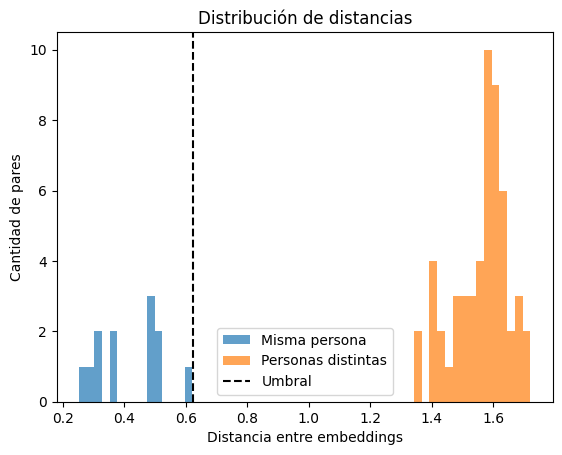

In [ ]:
import itertools
import numpy as np

@torch.no_grad()
def emb_ruta(ruta):
    model.eval()
    x = tf_test(Image.open(ruta).convert('RGB')).unsqueeze(0).to(device)
    return model(x)[0]

# Embeddings de las fotos de prueba (4 personas x 3 fotos)
items = [(p, r) for p, rutas in test.items() for r in rutas]
embs = [emb_ruta(r) for _, r in items]

mismas, distintas = [], []
for i, j in itertools.combinations(range(len(items)), 2):
    d = torch.norm(embs[i] - embs[j]).item()
    (mismas if items[i][0] == items[j][0] else distintas).append(d)

print(f"Pares misma persona:    {len(mismas)}  | distancia media: {np.mean(mismas):.3f}")
print(f"Pares personas distintas: {len(distintas)} | distancia media: {np.mean(distintas):.3f}")

# Buscar el mejor umbral
mejor_u, mejor_acc = 0, 0
for u in np.linspace(0, 2, 200):
    acc = (sum(d < u for d in mismas) + sum(d >= u for d in distintas)) / (len(mismas) + len(distintas))
    if acc > mejor_acc:
        mejor_u, mejor_acc = u, acc
print(f"\nMejor umbral: {mejor_u:.3f} | Accuracy en verificación: {mejor_acc:.2%}")

plt.hist(mismas, bins=15, alpha=0.7, label='Misma persona')
plt.hist(distintas, bins=15, alpha=0.7, label='Personas distintas')
plt.axvline(mejor_u, color='k', linestyle='--', label='Umbral')
plt.xlabel('Distancia entre embeddings'); plt.ylabel('Cantidad de pares')
plt.legend(); plt.title('Distribución de distancias')
plt.show()

### 9.2 One-shot Learning
Se usa **una sola foto de referencia por persona**. Cada foto de consulta se asigna a la persona cuya
referencia tenga el embedding más cercano. La última persona nunca se vio durante el fine-tuning, así que
su resultado ilustra el reconocimiento de una persona nueva (caso cercano a Zero-shot).

In [ ]:
# Galería: UNA sola foto de referencia por persona (incluida persona_05)
referencias = {p: rutas[0] for p, rutas in train.items()}
referencias['Persona_5'] = oneshot['Persona_5'][0]
emb_ref = {p: emb_ruta(r) for p, r in referencias.items()}

# Consultas: fotos de prueba de las 4 + las otras 9 de persona_05
consultas = [(p, r) for p, rutas in test.items() for r in rutas]
consultas += [('Persona_5', r) for r in oneshot['Persona_5'][1:]]

correctos = 0
for real, ruta in consultas:
    e = emb_ruta(ruta)
    pred = min(emb_ref, key=lambda p: torch.norm(e - emb_ref[p]).item())
    correctos += (pred == real)

print(f"One-shot (1 foto de referencia por persona): {correctos}/{len(consultas)} = {correctos/len(consultas):.2%}")

# Solo persona_05 (nunca vista en el entrenamiento)
c5 = [(p, r) for p, r in consultas if p == 'Persona_5']
ok5 = sum(min(emb_ref, key=lambda q: torch.norm(emb_ruta(r) - emb_ref[q]).item()) == p for p, r in c5)
print(f"Solo Persona_5 (no vista al entrenar): {ok5}/{len(c5)} = {ok5/len(c5):.2%}")

One-shot (1 foto de referencia por persona): 21/21 = 100.00%
Solo Persona_5 (no vista al entrenar): 9/9 = 100.00%


### 9.3 Few-shot Learning
Se usan **3 fotos de referencia por persona**; el prototipo de cada persona es el promedio de sus embeddings.

In [ ]:
refs, consultas_fs = {}, []
for p, rutas in train.items():
    refs[p] = rutas[:3]
    consultas_fs += [(p, r) for r in test[p]]
refs['Persona_5'] = oneshot['Persona_5'][:3]
consultas_fs += [('Persona_5', r) for r in oneshot['Persona_5'][3:]]

proto = {p: torch.stack([emb_ruta(r) for r in rs]).mean(0) for p, rs in refs.items()}

ok = 0
for real, ruta in consultas_fs:
    e = emb_ruta(ruta)
    pred = min(proto, key=lambda q: torch.norm(e - proto[q]).item())
    ok += (pred == real)
print(f"Few-shot (3 fotos por persona): {ok}/{len(consultas_fs)} = {ok/len(consultas_fs):.2%}")

Few-shot (3 fotos por persona): 19/19 = 100.00%


### 9.4 Resumen conceptual: One-shot, Few-shot y Zero-shot

| Escenario | Ejemplos por clase nueva | En este trabajo |
|---|---|---|
| **One-shot** | 1 | 1 foto de referencia por persona |
| **Few-shot** | pocos (2 a 5) | 3 fotos de referencia por persona |
| **Zero-shot** | 0 | Estrictamente, reconocer una clase sin ningún ejemplo; aquí se ilustra con una persona ajena al fine-tuning |

## 10. Evidencia visual de pares

Pares de fotos de prueba con su distancia y el veredicto del modelo según el umbral.

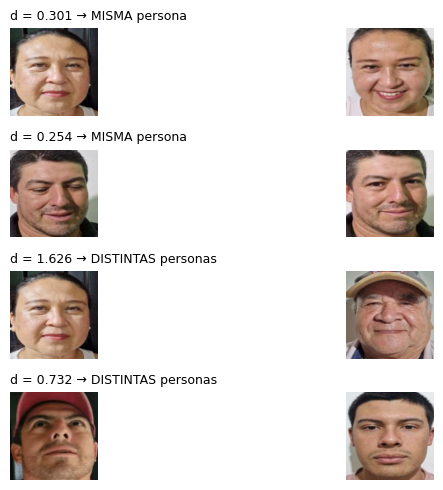

In [ ]:
umbral = mejor_u
pares = [
    (test['Persona_1'][0], test['Persona_1'][1]),            # misma persona
    (test['Persona_2'][0], test['Persona_2'][2]),            # misma persona
    (test['Persona_1'][0], test['Persona_3'][0]),            # distintas
    (test['Persona_2'][1], oneshot['Persona_5'][0]),         # distintas
]

plt.figure(figsize=(9, 5))
for i, (r1, r2) in enumerate(pares):
    d = torch.norm(emb_ruta(r1) - emb_ruta(r2)).item()
    veredicto = "MISMA persona" if d < umbral else "DISTINTAS personas"
    for k, r in enumerate([r1, r2]):
        plt.subplot(len(pares), 2, i * 2 + k + 1)
        plt.imshow(Image.open(r))
        plt.axis('off')
        if k == 0:
            plt.title(f"d = {d:.3f} → {veredicto}", fontsize=9, loc='left')
plt.tight_layout()
plt.show()

## 11. Resultados, limitaciones y conclusiones

**Resultados**
- Verificación de pares: separación clara entre distancias de la misma persona y de personas distintas.
- One-shot, Few-shot y persona no vista: clasificación correcta en las pruebas realizadas.
- La Triplet Loss fue ≈ 0 desde la primera época, incluso con negativos difíciles.

**Limitaciones**
- Dataset pequeño (5 personas, 10 fotos por persona): un 100 % no garantiza el mismo desempeño con más
  personas, otras cámaras o condiciones de iluminación difíciles.
- El umbral se eligió con los mismos pares de prueba, lo que puede inflar ligeramente la accuracy.
- El buen resultado se debe en gran parte al **preentrenamiento en VGGFace2**, no a un aprendizaje nuevo
  del fine-tuning. La persona "no vista" lo fue solo durante el fine-tuning.

**Conclusiones**
- Una red siamesa con Triplet Loss produce embeddings que permiten verificar identidades comparando distancias.
- El preprocesamiento (detección, recorte y normalización) es fundamental para la calidad del reconocimiento.
- El mismo modelo permite One-shot y Few-shot sin reentrenar, solo cambiando las imágenes de referencia.